In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar nuestro paquete de src/ sin instalarlo
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 07 · Validación e interpretación — abrir la prueba, una sola vez

**Especificación:** `specs/005-validacion/spec.md` (aprobada el 2026-11-05) · **Plan:** `specs/005-validacion/plan.md`

Hasta aquí **nadie ha mirado el conjunto de prueba** (`data/processed/test.parquet`). Hoy se abre, con reglas estrictas:

1. Las decisiones (modelo, parámetros, calibración, umbral) se toman **antes** y se **escriben**, solo con entrenamiento.
2. La prueba se abre **una vez**, con `open_test_once`: deja una marca en `reports/prueba_abierta.txt` y **se niega a abrirla de nuevo**.
3. Lo que se vea en la prueba **no cambia el modelo**. Si algo no gusta, se anota como límite en `reports/07_validacion.md`.

> **Ejecutar este notebook completo una sola vez** (tarea T010). Si falla después de abrir la prueba, no se borra la marca:
> se arregla el error y se continúa desde la celda que falló, declarándolo en el reporte.

## 0. Cargar el entrenamiento y conectar MLflow

Cada cliente aparece una sola vez (`id` único), así que partir y remuestrear por fila es partir y remuestrear por cliente.

In [2]:
%pip install lightgbm==4.7.0 shap==0.54.1

Note: you may need to restart the kernel to use updated packages.


In [3]:
import json
import subprocess
from datetime import datetime

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
from sklearn.calibration import calibration_curve
from sklearn.model_selection import train_test_split

from proyecto.config import (CATEGORY_MAPS, COST_MATRIX, ID_COL, MIN_REGION_SIZE, PROCESSED_DIR, ROOT, SENSITIVITY_RATIOS,
                             TARGET, TEST_MARKER, TUNE_HOLDOUT, TUNE_SEED)
from proyecto.models.train import BusinessRuleClassifier, cost_threshold, decide, metrics_from_proba, split_xy
from proyecto.models.tuning import bootstrap_cost_difference
from proyecto.models.validation import (age_band, bootstrap_log_loss_difference, bootstrap_mean, cost_sensitivity,
                                        fit_final_model, open_test_once, segment_table, should_calibrate)
from proyecto.tracking.mlflow_utils import configure_mlflow, set_experiment

REPORTS = ROOT / "reports"
MODELS = ROOT / "models"
train = pd.read_parquet(PROCESSED_DIR / "train.parquet")
assert train[ID_COL].is_unique, "un cliente aparece más de una vez: habría que partir por grupo"
print(f"entrenamiento: {train.shape[0]:,} filas x {train.shape[1]} columnas · ID_COL = {ID_COL!r} · TARGET = {TARGET!r}")
print("la prueba sigue CERRADA:", "sí" if not TEST_MARKER.exists() else "NO — ya existe la marca, ver reports/prueba_abierta.txt")

entrenamiento: 304,238 filas x 12 columnas · ID_COL = 'id' · TARGET = 'Response'
la prueba sigue CERRADA: sí


In [4]:
with warnings.catch_warnings(record=True) as avisos:   # mostramos por qué se usó (o no) Databricks
    warnings.simplefilter("always")
    donde = configure_mlflow()
for aviso in avisos:
    print("Aviso:", aviso.message)
experimento = set_experiment("venta-cruzada-validacion")
print("MLflow:", donde, "| experimento:", experimento)

2026/11/05 20:43:42 INFO mlflow.tracking.fluent: Experiment with name 'venta-cruzada-validacion' does not exist. Creating a new experiment.


MLflow: local | experimento: venta-cruzada-validacion


## 1. Decisiones congeladas — **antes** de abrir la prueba

Salen de las etapas anteriores, nunca de la prueba. La calibración queda en `None`: la fija la sección 2 aplicando la regla escrita.

In [5]:
best = json.loads((REPORTS / "06_best_params.json").read_text(encoding="utf-8"))
assert best["finalista"] == "lightgbm" and best["decision"] == "optimizado", "06_best_params.json no dice lo que se aprobó"
PARAMS = best["parametros"]

DECISIONES = {
    "modelo_final": "lightgbm",
    "parametros": PARAMS,                                   # los optimizados (IC 95 % de la mejora todo bajo cero en la etapa 06)
    "variables": "base + 5 nuevas (use_engineered=True), con Gender, sin Policy_Sales_Channel",
    "entrenamiento_final": "todo train.parquet",
    "calibrar": None,                                       # lo fija la sección 2 con la regla de la spec
    "metrica_principal": "costo esperado por cliente, matriz [[0, 1], [5, 0]] (menor es mejor)",
    "regla_de_decision": f"llamar si P(interesado) > 1/6 = {cost_threshold():.4f} (umbral fijo, sale de la matriz)",
    "linea_base": "regla: Previously_Insured = 0 y Vehicle_Damage = Yes",
    "lectura": "el modelo es mejor que la línea base solo si todo el IC 95 % de (costo modelo − costo línea base) está bajo cero",
    "decidido_el": None,                                    # se escribe al terminar la sección 2
}
print(json.dumps({k: v for k, v in DECISIONES.items() if k != "parametros"}, indent=2, ensure_ascii=False))
print("parámetros:", {k: round(v, 4) if isinstance(v, float) else v for k, v in PARAMS.items()})

{
  "modelo_final": "lightgbm",
  "variables": "base + 5 nuevas (use_engineered=True), con Gender, sin Policy_Sales_Channel",
  "entrenamiento_final": "todo train.parquet",
  "calibrar": null,
  "metrica_principal": "costo esperado por cliente, matriz [[0, 1], [5, 0]] (menor es mejor)",
  "regla_de_decision": "llamar si P(interesado) > 1/6 = 0.1667 (umbral fijo, sale de la matriz)",
  "linea_base": "regla: Previously_Insured = 0 y Vehicle_Damage = Yes",
  "lectura": "el modelo es mejor que la línea base solo si todo el IC 95 % de (costo modelo − costo línea base) está bajo cero",
  "decidido_el": null
}
parámetros: {'n_estimators': 186, 'learning_rate': 0.0315, 'num_leaves': 31, 'min_child_samples': 137, 'subsample': 0.943, 'colsample_bytree': 0.601, 'reg_lambda': 0.478}


## 2. ¿Hay que calibrar las probabilidades? (con la reserva de la etapa 06, nunca con la prueba)

La decisión de llamar usa la **probabilidad** (umbral 1/6), así que tiene que ser creíble. Se usa la **misma reserva** de la
etapa 06 (25 % del entrenamiento, estratificado, semilla 7): los dos modelos se entrenan con el 75 % y se miden en el 25 %.

**Regla escrita antes de mirar** (spec, con la enmienda del 2026-11-05): se calibra solo si **(1)** todo el intervalo del 95 % de
(log loss calibrado − sin calibrar) está bajo cero **y** **(2)** el costo de negocio en la reserva no sube.

In [6]:
tune_df, holdout_df = train_test_split(train, test_size=TUNE_HOLDOUT, stratify=train[TARGET], random_state=TUNE_SEED)
assert set(tune_df[ID_COL]).isdisjoint(set(holdout_df[ID_COL])), "hay clientes en los dos lados"
X_hold, y_hold = split_xy(holdout_df)
print(f"ajuste: {len(tune_df):,} clientes · reserva: {len(holdout_df):,} clientes ({y_hold.mean():.2%} interesados)")

raw_model = fit_final_model(tune_df, PARAMS, calibrate=False)
cal_model = fit_final_model(tune_df, PARAMS, calibrate=True)
p_raw = raw_model.predict_proba(X_hold)[:, 1]
p_cal = cal_model.predict_proba(X_hold)[:, 1]
m_raw, m_cal = metrics_from_proba(y_hold, p_raw), metrics_from_proba(y_hold, p_cal)

show = ["cost", "contact_rate", "recall", "precision", "pr_auc", "log_loss", "brier"]
calib_table = pd.DataFrame({"sin calibrar": m_raw, "calibrado": m_cal}).loc[show]
calib_table["diferencia (cal. − sin cal.)"] = calib_table["calibrado"] - calib_table["sin calibrar"]
calib_table.round(4)

ajuste: 228,178 clientes · reserva: 76,060 clientes (12.27% interesados)


,sin calibrar,calibrado,diferencia (cal. − sin cal.)
cost,0.3303,0.3304,0.0001
contact_rate,0.3644,0.3682,0.0038
recall,0.8796,0.8847,0.0050
precision,0.2961,0.2947,-0.0014
pr_auc,0.3530,0.3514,-0.0016
log_loss,0.2678,0.2678,-0.0001
brier,0.0877,0.0878,0.0000


In [7]:
ll_diff = bootstrap_log_loss_difference(y_hold, p_cal, p_raw, n_boot=1000)
cost_diff_cal = bootstrap_cost_difference(y_hold, p_cal, p_raw, n_boot=1000)
CALIBRAR = should_calibrate(m_raw, m_cal, ll_diff)

print(f"log loss calibrado − sin calibrar = {ll_diff[0]:+.5f}  IC 95 % [{ll_diff[1]:+.5f}, {ll_diff[2]:+.5f}]"
      f"  → condición 1 {'se cumple' if ll_diff[2] < 0 else 'NO se cumple'}")
print(f"costo    calibrado − sin calibrar = {m_cal['cost'] - m_raw['cost']:+.5f}"
      f"  (IC 95 % [{cost_diff_cal[1]:+.5f}, {cost_diff_cal[2]:+.5f}], informativo)"
      f"  → condición 2 {'se cumple' if m_cal['cost'] <= m_raw['cost'] else 'NO se cumple'}")
print("DECISIÓN:", "se CALIBRA (isotónica, 3 pliegues)" if CALIBRAR else "NO se calibra")

DECISIONES["calibrar"] = bool(CALIBRAR)
DECISIONES["decidido_el"] = datetime.now().isoformat(timespec="seconds")
(REPORTS / "07_decisiones_congeladas.json").write_text(json.dumps(DECISIONES, indent=2, ensure_ascii=False), encoding="utf-8")
print("decisiones congeladas el", DECISIONES["decidido_el"], "→ reports/07_decisiones_congeladas.json")

log loss calibrado − sin calibrar = -0.00008  IC 95 % [-0.00025, +0.00010]  → condición 1 NO se cumple
costo    calibrado − sin calibrar = +0.00011  (IC 95 % [-0.00126, +0.00146], informativo)  → condición 2 NO se cumple
DECISIÓN: NO se calibra
decisiones congeladas el 2026-11-05T20:43:52 → reports/07_decisiones_congeladas.json


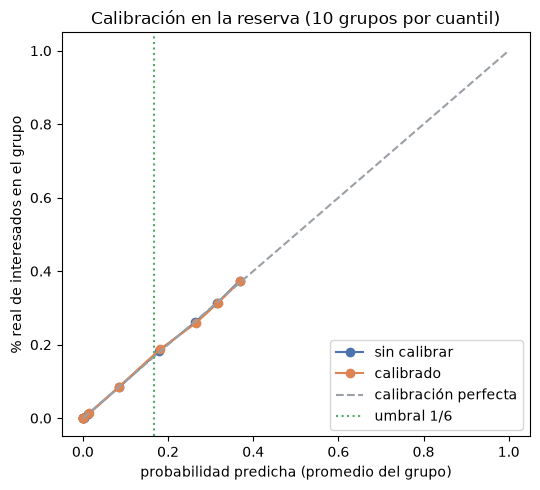

In [8]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for name, proba, color in [("sin calibrar", p_raw, "#4c72b0"), ("calibrado", p_cal, "#dd8452")]:
    frac, mean_pred = calibration_curve(y_hold, proba, n_bins=10, strategy="quantile")
    ax.plot(mean_pred, frac, "o-", color=color, label=name)
ax.plot([0, 1], [0, 1], "--", color="#9aa0a6", label="calibración perfecta")
ax.axvline(cost_threshold(), color="#55a868", ls=":", label="umbral 1/6")
ax.set_xlabel("probabilidad predicha (promedio del grupo)"); ax.set_ylabel("% real de interesados en el grupo")
ax.set_title("Calibración en la reserva (10 grupos por cuantil)"); ax.legend()
plt.tight_layout(); fig.savefig(REPORTS / "07_calibracion.png", dpi=120); plt.show()

## 3. Modelo final con **todo** el entrenamiento

Mismas decisiones, ahora con el 100 % de `train.parquet`. Se guarda entero (variables nuevas + preprocesamiento + modelo) en
`models/final_pipeline.joblib` para registrarlo en el notebook 08 (no se sube a GitHub).

In [9]:
X_train, y_train = split_xy(train)
final_model = fit_final_model(train, PARAMS, calibrate=DECISIONES["calibrar"])
joblib.dump(final_model, MODELS / "final_pipeline.joblib")
print(f"modelo final: {type(final_model).__name__} · entrenado con {len(train):,} clientes → models/final_pipeline.joblib")

# Línea base: la regla de negocio aprende su tasa de interés solo con el entrenamiento
baseline = BusinessRuleClassifier().fit(X_train, y_train)
print(f"línea base: tasa con regla {baseline.rate_rule_:.2%} · sin regla {baseline.rate_other_:.2%} (umbral {cost_threshold():.2%})")

modelo final: Pipeline · entrenado con 304,238 clientes → models/final_pipeline.joblib
línea base: tasa con regla 25.03% · sin regla 0.54% (umbral 16.67%)


## 4. Abrir la prueba — **una sola vez**

A partir de aquí **no se cambia nada del modelo**. `open_test_once` comprueba que no exista la marca y que todas las decisiones
estén completas; si no, se detiene sin leer el archivo.

In [10]:
try:
    commit = subprocess.run(["git", "rev-parse", "--short", "HEAD"], capture_output=True, text=True, cwd=ROOT).stdout.strip()
except (FileNotFoundError, OSError):
    commit = ""
test = open_test_once(TEST_MARKER, PROCESSED_DIR / "test.parquet", DECISIONES, commit=commit or "desconocido")
assert test[ID_COL].is_unique and set(test[ID_COL]).isdisjoint(set(train[ID_COL])), "hay clientes en entrenamiento y prueba"
X_test, y_test = split_xy(test)
print(TEST_MARKER.read_text(encoding="utf-8"))
print(f"prueba: {len(test):,} clientes ({y_test.mean():.2%} interesados) — primera y única evaluación")

Prueba abierta una sola vez (specs/005-validacion)
fecha: 2026-11-05T20:43:56
usuario: andir
commit: e94c0cb
archivo: test.parquet (76222 filas)

prueba: 76,222 clientes (12.26% interesados) — primera y única evaluación


In [11]:
p_model = final_model.predict_proba(X_test)[:, 1]
p_base = baseline.predict_proba(X_test)[:, 1]
m_model, m_base = metrics_from_proba(y_test, p_model), metrics_from_proba(y_test, p_base)
d_model, d_base = decide(p_model), decide(p_base)

show = ["cost", "contact_rate", "recall", "precision", "pr_auc", "roc_auc", "capture_20", "capture_30", "capture_50", "log_loss"]
test_table = pd.DataFrame({"modelo": m_model, "línea base (regla)": m_base}).loc[show]
test_table["diferencia (modelo − regla)"] = test_table["modelo"] - test_table["línea base (regla)"]
print("Nota: la regla solo da 2 probabilidades distintas; su PR-AUC, ROC-AUC y captura son de referencia, no comparables 1 a 1.")
test_table.round(4)

Nota: la regla solo da 2 probabilidades distintas; su PR-AUC, ROC-AUC y captura son de referencia, no comparables 1 a 1.


,modelo,línea base (regla),diferencia (modelo − regla)
cost,0.3312,0.3720,-0.0408
contact_rate,0.3650,0.4779,-0.1129
recall,0.8793,0.9773,-0.0981
precision,0.2952,0.2506,0.0446
pr_auc,0.3531,0.2477,0.1053
roc_auc,0.8515,0.7846,0.0669
capture_20,0.5640,0.4080,0.1560
capture_30,0.7787,0.6183,0.1605
capture_50,0.9892,0.9784,0.0108
log_loss,0.2675,0.2864,-0.0189


## 5. Intervalos del 95 % y comparación con la línea base

*Bootstrap* de clientes (1.000 remuestreos, semilla 42). **Regla de lectura, escrita antes de mirar:** el modelo es mejor que la
regla de negocio solo si **todo** el intervalo de (costo modelo − costo regla) está **bajo cero**.

In [12]:
cost = np.asarray(COST_MATRIX, dtype=float)
ci_model = bootstrap_mean(cost[y_test, d_model], n_boot=1000)
ci_base = bootstrap_mean(cost[y_test, d_base], n_boot=1000)
ci_diff = bootstrap_cost_difference(y_test, p_model, p_base, n_boot=1000)

beats_baseline = ci_diff[2] < 0
verdict = ("SÍ: todo el intervalo está bajo cero" if beats_baseline else
           "NO hay evidencia: el intervalo cruza el cero" if ci_diff[1] <= 0 <= ci_diff[2] else
           "NO: el modelo cuesta más (todo el intervalo sobre cero)")
print(f"costo modelo         = {ci_model[0]:.4f}  IC 95 % [{ci_model[1]:.4f}, {ci_model[2]:.4f}]")
print(f"costo línea base     = {ci_base[0]:.4f}  IC 95 % [{ci_base[1]:.4f}, {ci_base[2]:.4f}]")
print(f"modelo − línea base  = {ci_diff[0]:+.4f}  IC 95 % [{ci_diff[1]:+.4f}, {ci_diff[2]:+.4f}]  → ¿mejor que la regla? {verdict}")
print(f"por cada 10.000 clientes: {ci_diff[0] * 10_000:+.0f} unidades de costo (1 = llamada sin éxito; 5 = interesado perdido)")

costo modelo         = 0.3312  IC 95 % [0.3263, 0.3364]
costo línea base     = 0.3720  IC 95 % [0.3682, 0.3759]
modelo − línea base  = -0.0408  IC 95 % [-0.0453, -0.0362]  → ¿mejor que la regla? SÍ: todo el intervalo está bajo cero
por cada 10.000 clientes: -408 unidades de costo (1 = llamada sin éxito; 5 = interesado perdido)


## 6. Errores por segmento, carga de trabajo y sensibilidad (solo se reportan)

Segmentos: `Gender`, tramos de `Age` (18–29, 30–44, 45–59, 60+) y `Region_Code` (regiones con menos de 1.000 clientes en la
prueba se agrupan como "otras"). **Señal de alarma:** un segmento donde el % contactado y el % real se separan mucho, o donde
el recall cae muy por debajo del general.

In [13]:
gender_names = {code: name for name, code in CATEGORY_MAPS["Gender"].items()}
segment_sources = {
    "Gender": X_test["Gender"].map(gender_names),
    "Age": age_band(X_test["Age"]).to_numpy(),
    "Region_Code": X_test["Region_Code"],
}
segments = pd.concat(
    [segment_table(values, y_test, d_model, min_size=MIN_REGION_SIZE if name == "Region_Code" else None).assign(variable=name)
     for name, values in segment_sources.items()],
    ignore_index=True,
)
segments["gap_contact_vs_real"] = segments["contact_rate"] - segments["positive_rate"]
segments = segments[["variable", "segment", "clients", "cost", "contact_rate", "positive_rate", "gap_contact_vs_real", "recall"]]
segments.to_csv(REPORTS / "07_segmentos.csv", index=False)
print(f"general: costo {m_model['cost']:.4f} · contactado {m_model['contact_rate']:.2%} · real {y_test.mean():.2%}"
      f" · recall {m_model['recall']:.2%}")
segments.round(4)

general: costo 0.3312 · contactado 36.50% · real 12.26% · recall 87.93%


,variable,segment,clients,cost,contact_rate,positive_rate,gap_contact_vs_real,recall
0,Gender,Male,41309,0.3671,0.4209,0.1398,0.2811,0.8975
1,Gender,Female,34913,0.2888,0.2989,0.1022,0.1967,0.8498
2,Age,18-29,31037,0.1676,0.0811,0.0411,0.0400,0.4828
3,Age,30-44,18848,0.4247,0.6029,0.2050,0.3980,0.9783
4,Age,45-59,17060,0.4795,0.6539,0.1920,0.4619,0.9847
5,Age,60+,9277,0.4162,0.3001,0.0999,0.2002,0.6397
6,Region_Code,28,21263,0.4445,0.5672,0.1876,0.3796,0.9424
7,Region_Code,otras,16859,0.3188,0.2851,0.0944,0.1906,0.7739
8,Region_Code,8,6739,0.2785,0.3214,0.0999,0.2215,0.9049
9,Region_Code,46,3902,0.2911,0.3119,0.1053,0.2066,0.8662


In [14]:
workload = pd.DataFrame({
    "% de la base a llamar": [d_model.mean(), d_base.mean()],
    "% real de interesados": [y_test.mean(), y_test.mean()],
    "llamadas por interesado encontrado": [d_model.sum() / max((d_model * y_test).sum(), 1),
                                           d_base.sum() / max((d_base * y_test).sum(), 1)],
}, index=["modelo", "línea base (regla)"])

sensitivity = pd.DataFrame({
    "modelo": cost_sensitivity(y_test, d_model, SENSITIVITY_RATIOS),
    "línea base (regla)": cost_sensitivity(y_test, d_base, SENSITIVITY_RATIOS),
})
sensitivity.index = [f"{r} a 1" for r in sensitivity.index]
sensitivity["diferencia (modelo − regla)"] = sensitivity["modelo"] - sensitivity["línea base (regla)"]
print("Carga de trabajo:"); display(workload.round(4))
print("Sensibilidad del costo (misma decisión, umbral 1/6; solo reporte, el umbral NO se cambia):"); display(sensitivity.round(4))

Carga de trabajo:


,% de la base a llamar,% real de interesados,llamadas por interesado encontrado
modelo,0.3650,0.1226,3.3870
línea base (regla),0.4779,0.1226,3.9898


Sensibilidad del costo (misma decisión, umbral 1/6; solo reporte, el umbral NO se cambia):


,modelo,línea base (regla),diferencia (modelo − regla)
3 a 1,0.3016,0.3665,-0.0648
5 a 1,0.3312,0.3720,-0.0408
10 a 1,0.4052,0.3859,0.0193


## 7. ¿Por qué decide así el modelo? (SHAP)

Valores SHAP del LightGBM final en una muestra de 5.000 clientes de la prueba. Tres límites: **explican al modelo, no al mundo**
(no dicen si acertó); las variables **correlacionadas se reparten el crédito**; una importancia alta **no es causa**.
`Gender`, `Age` y `Region_Code` son **atributos sensibles**: se declaran en el reporte y en la ficha.

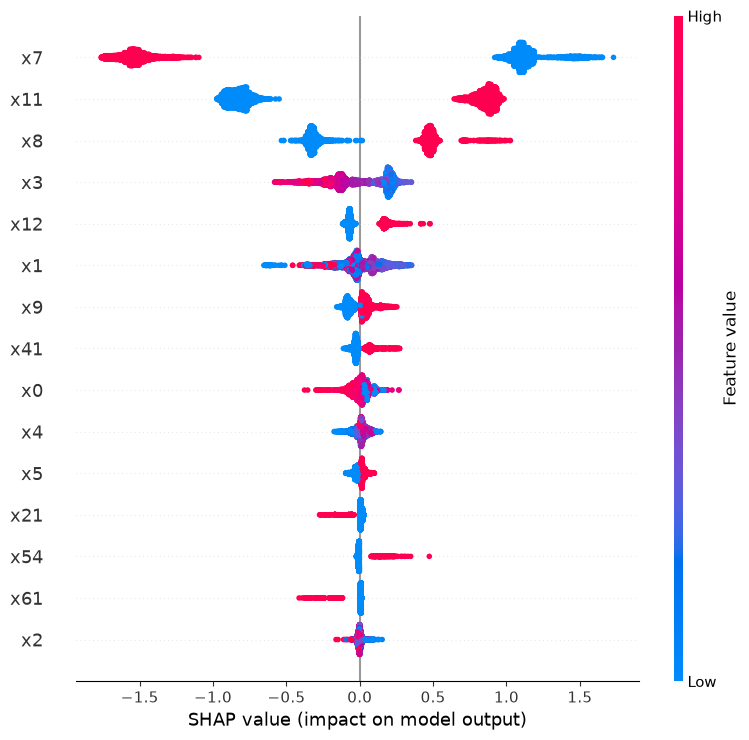

,|SHAP| promedio
x7,1.3184
x11,0.8432
x8,0.4079
x3,0.1814
x12,0.1138
...,...
x37,0.0000
x18,0.0000
x53,0.0000
x26,0.0000


In [15]:
import shap

# Si se calibró, SHAP explica el LightGBM de dentro del primer pliegue de calibración (se dice en el reporte)
pipeline = final_model.calibrated_classifiers_[0].estimator if DECISIONES["calibrar"] else final_model
lgbm, transform = pipeline.named_steps["model"], pipeline[:-1]

sample = X_test.sample(n=min(5000, len(X_test)), random_state=42)
X_sample = transform.transform(sample)
try:
    feature_names = list(transform.get_feature_names_out())
except Exception:
    feature_names = [f"x{i}" for i in range(X_sample.shape[1])]
X_sample = pd.DataFrame(np.asarray(X_sample, dtype=float), columns=feature_names)

values = shap.TreeExplainer(lgbm).shap_values(X_sample)
values = values[1] if isinstance(values, list) else values          # algunas versiones devuelven una lista por clase
importance = pd.Series(np.abs(values).mean(axis=0), index=feature_names, name="|SHAP| promedio").sort_values(ascending=False)

shap.summary_plot(values, X_sample, show=False, max_display=15)
plt.tight_layout(); plt.savefig(REPORTS / "07_shap.png", dpi=120, bbox_inches="tight"); plt.show()
importance.round(4).to_frame()

## 8. Guardar los resultados y registrar en MLflow

Todas las cifras de `reports/07_metricas_test.json` salen de aquí (ninguna se escribe a mano). El notebook 08 las registra junto al modelo.

In [16]:
def as_interval(ci):
    return {"valor": ci[0], "ic95": [ci[1], ci[2]]}

results = {
    "decisiones": DECISIONES,
    "calibracion_reserva": {"sin_calibrar": m_raw, "calibrado": m_cal, "log_loss_diferencia": as_interval(ll_diff)},
    "prueba": {
        "clientes": int(len(y_test)),
        "tasa_interesados": float(y_test.mean()),
        "modelo": {**m_model, "cost_ic95": [ci_model[1], ci_model[2]]},
        "linea_base": {**m_base, "cost_ic95": [ci_base[1], ci_base[2]]},
        "diferencia_costo": as_interval(ci_diff),
        "mejor_que_linea_base": bool(beats_baseline),
        "sensibilidad": {f"{r}_a_1": {"modelo": m, "linea_base": b}
                         for r, m, b in zip(SENSITIVITY_RATIOS, sensitivity["modelo"], sensitivity["línea base (regla)"])},
    },
    "shap_top10": importance.head(10).to_dict(),
    "prueba_abierta": TEST_MARKER.read_text(encoding="utf-8"),
}
(REPORTS / "07_metricas_test.json").write_text(json.dumps(results, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
print("guardado: reports/07_metricas_test.json · 07_segmentos.csv · 07_calibracion.png · 07_shap.png")

guardado: reports/07_metricas_test.json · 07_segmentos.csv · 07_calibracion.png · 07_shap.png


In [17]:
with mlflow.start_run(run_name="validacion-final") as run:
    mlflow.set_tags({"etapa": "07_validacion", "modelo": "lightgbm", "calibrado": str(DECISIONES["calibrar"]),
                     "mejor_que_linea_base": str(beats_baseline), "commit": commit or "desconocido"})
    mlflow.log_params(PARAMS)
    mlflow.log_metrics({f"test_{k}": float(v) for k, v in m_model.items()})
    mlflow.log_metrics({f"test_baseline_{k}": float(v) for k, v in m_base.items()})
    mlflow.log_metrics({"test_cost_low": ci_model[1], "test_cost_high": ci_model[2],
                        "test_cost_diff": ci_diff[0], "test_cost_diff_low": ci_diff[1], "test_cost_diff_high": ci_diff[2],
                        "holdout_log_loss_diff": ll_diff[0], "holdout_log_loss_diff_high": ll_diff[2]})
    mlflow.log_metrics({f"test_cost_{r}_to_1": float(v) for r, v in zip(SENSITIVITY_RATIOS, sensitivity["modelo"])})
    for name in ["07_metricas_test.json", "07_segmentos.csv", "07_calibracion.png", "07_shap.png", "prueba_abierta.txt"]:
        mlflow.log_artifact(str(REPORTS / name))
    print("MLflow:", donde, "| run_id:", run.info.run_id)

MLflow: local | run_id: 231873a7c3ff45d798252037407d9451
